# Colab 2 — Bayesian regression, MCMC diagnostics, hierarchy
## Palmer penguins: mass vs flipper length by species

**Original notebook covered:** `6_2_PyMC_MCMC` (pooled Bayesian OLS, posterior predictive bands, grid approximation, hierarchical regression, Neal’s funnel, centered vs non-centered, ESS / $\hat R$ / divergences).

**This notebook uses a different dataset:** seaborn `penguins`. Body mass vs flipper length, grouped by species — a real Simpson-style grouping, not the synthetic 5-group cloud from the lecture.

**Classical counterparts** from `3_statsmodels_OLS`: `sm.OLS`, residual plots, QQ, influence, dummy variables, VIF. Confidence intervals for the mean line sit next to Bayesian HDIs and predictive intervals.

CPU runtime: pooled models ~1 minute; hierarchical ~2–4 minutes.

**Assignment format.** Lecture questions from `6_2` and the relevant `3_statsmodels_OLS` prompts are quoted and answered in place.



In [1]:
# Colab setup — run once
import sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip -q install pymc arviz graphviz
    !apt-get -qq install -y graphviz > /dev/null
print("Ready. Runtime → Change runtime type → CPU is enough.")



Ready. Runtime → Change runtime type → CPU is enough.


In [2]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor as VIF

import arviz as az
import pymc as pm

az.style.use("arviz-darkgrid")
np.random.seed(2)

def show_model(model):
    try:
        g = pm.model_to_graphviz(model)
        from IPython.display import display
        display(g)
    except Exception as exc:
        print("graphviz not available:", exc)
        print(model)



## 1. Data and Simpson’s paradox

**Simpson in one sentence:** a trend that appears (or reverses) when groups are pooled can disappear (or flip) inside each group. **What to do:** model the grouping, do not only fit the pooled line.

Famous cases: Berkeley admissions (1973) and some COVID-19 fatality comparisons across hospitals / countries — crude pooling mixed different case mixes.



          x_raw                           y                         
          count        mean       std count         mean         std
group                                                               
Adelie      151  189.953642  6.539457   151  3700.662252  458.566126
Chinstrap    68  195.823529  7.131894    68  3733.088235  384.335081
Gentoo      123  217.186992  6.484976   123  5076.016260  504.116237


,species,island,bill_length_mm,bill_depth_mm,x_raw,y,sex,x,group,group_idx
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male,-19.915205,Adelie,0
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female,-14.915205,Adelie,0
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female,-5.915205,Adelie,0
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female,-7.915205,Adelie,0
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male,-10.915205,Adelie,0


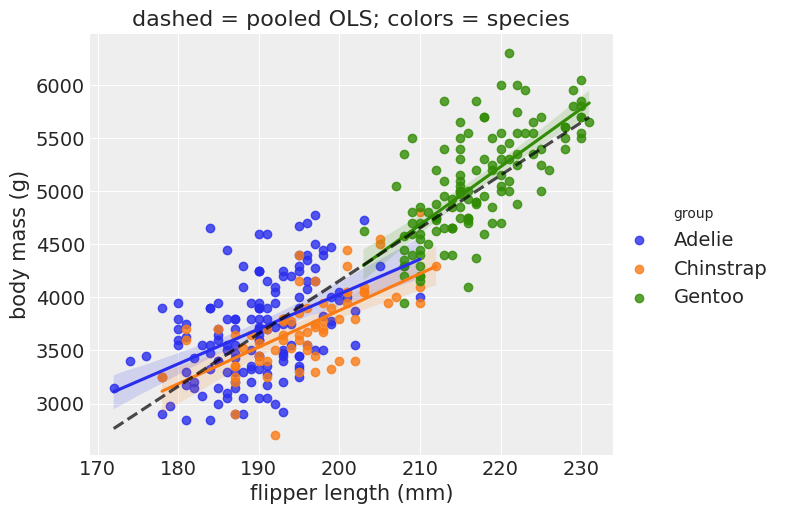

In [3]:
peng = sns.load_dataset("penguins").dropna(subset=["body_mass_g", "flipper_length_mm", "species"])
peng = peng.rename(columns={"body_mass_g": "y", "flipper_length_mm": "x_raw", "species": "species"})
# center x so intercepts are interpretable (mass at mean flipper)
peng["x"] = peng["x_raw"] - peng["x_raw"].mean()
species = peng["species"].astype("category")
peng["group"] = species.astype(str)
peng["group_idx"] = species.cat.codes.to_numpy()
group_list = list(species.cat.categories)

print(peng.groupby("group")[["x_raw", "y"]].agg(["count", "mean", "std"]))
display(peng.head())

g = sns.lmplot(data=peng, x="x_raw", y="y", hue="group", height=5, aspect=1.3)
sns.regplot(data=peng, x="x_raw", y="y", scatter=False, ci=None,
            line_kws=dict(color="k", ls="--", alpha=0.7), ax=g.axes[0, 0])
g.axes[0, 0].set_xlabel("flipper length (mm)")
g.axes[0, 0].set_ylabel("body mass (g)")
g.axes[0, 0].set_title("dashed = pooled OLS; colors = species")
plt.show()



---

**Lecture question**

Explain Simpson's paradox in one sentence, and the way to deal with it in another.
Give famous real-life examples. Mention the original Berkeley bias case and COVID-19 in Italy.

**Answer**

**Sentence 1.** A relationship in pooled data can weaken, vanish, or reverse inside every subgroup. **Sentence 2.** Condition on (or hierarchically model) the grouping variable; do not interpret the pooled slope as a within-group mechanism.

**Berkeley (1973).** Overall, women's admission rate was lower than men's. Department by department, women often did as well or better; they applied more to departments with lower admission rates. Sex was confounded with department.

**COVID Italy (and similar country comparisons).** Crude case-fatality ratios differed across regions or countries largely because of different age mixes and testing intensity. Age-stratified rates told a different story. Pooling over age is Simpson.

**Penguins.** Gentoo are both heavier and have longer flippers. The dashed pooled line partly compares *species* rather than "what happens if this bird's flipper grows 1 mm." Within-species slopes (colored) are the biological parameter. A pooled Bayesian regression has the same Simpson problem as pooled OLS — Bayes does not fix confounding.

**Criticism.** "Always stratify" can be wrong: if the grouping is a *collider* or a mediator you should not condition on, stratification biases a causal slope. Simpson is a reminder to name the target (within-species vs mixture), not a theorem that pooling is always invalid.



## 2. Classical OLS (pooled) — the statsmodels toolkit

$$
y = \beta_0 + \beta_1 x + \varepsilon, \quad \varepsilon \sim N(0,\sigma^2)
$$

OLS assumptions, compactly: $\mathbb{E}[\varepsilon \mid X]=0$, uncorrelated homoscedastic errors, and (for the usual SEs / $t$ tests) Gaussian errors — i.e. $y \mid X \sim N(X\beta, \sigma^2 I)$. Polynomial regression is still linear in the *parameters*.



In [4]:
design = sm.add_constant(peng["x"].to_numpy())
ols = sm.OLS(peng["y"].to_numpy(), design).fit()
print(ols.summary())



                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          4.37e-107
Time:                        07:34:10   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       4201.7544     21.320    197.079      0.0

**Reading `summary()` (the lecture checklist):**

- $R^2$: fraction of variance explained by the line.
- **F-statistic:** $H_0$: all slopes zero (here, one slope).
- **Omnibus / Jarque–Bera:** residual normality; “omnibus” in this printout is a skew+kurtosis test, not the ANOVA omnibus of a multi-factor design.
- **AIC / BIC:** predictive / marginal-likelihood penalties — later we compare them to WAIC.
- **P>|t|:** $H_0$: that coefficient is 0.

Residual plots: we want no trend vs fitted, roughly Gaussian QQ, no mega-outliers. Influence = leverage (hat-matrix diagonal $h_{ii}$, usually in $[0,1]$) × residual size.



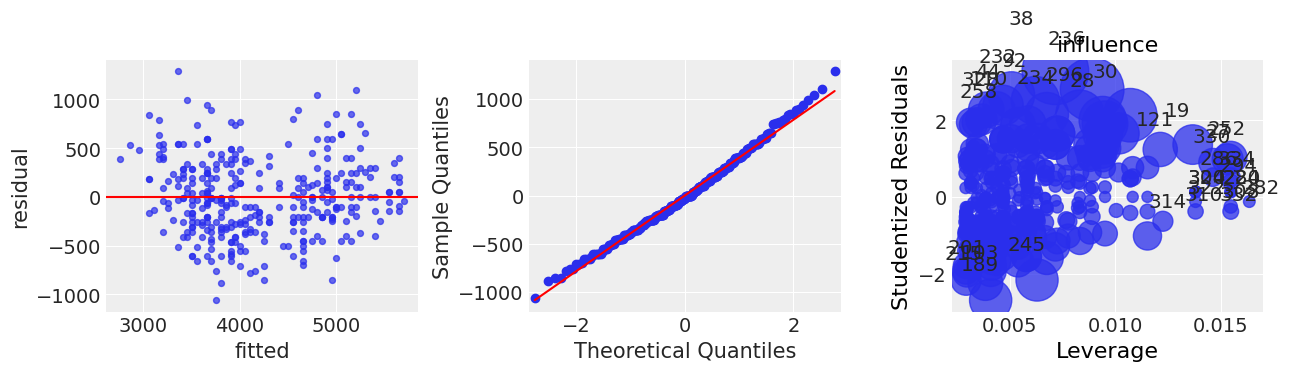

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].scatter(ols.fittedvalues, ols.resid, s=18, alpha=0.7)
axes[0].axhline(0, color="red")
axes[0].set_xlabel("fitted"); axes[0].set_ylabel("residual")
sm.graphics.qqplot(ols.resid, line="s", ax=axes[1])
ols.get_influence().plot_influence(ax=axes[2], criterion="cooks")
axes[2].set_title("influence")
plt.tight_layout()
plt.show()

# OLS mean CI and prediction interval on a grid (classical PI)
x_grid = np.linspace(peng["x"].min(), peng["x"].max(), 150)
pred = ols.get_prediction(sm.add_constant(x_grid))
pred_df = pred.summary_frame(alpha=0.05)



---

**Lecture question**

What are the assumptions of OLS? What happens if they're violated? Express them as a constraint on the joint distribution of the errors.
Why is polynomial regression a special case of linear regression?
Explain the statsmodels OLS output: R², F, Omnibus, AIC/BIC, P>|t|.
What should I look for in residual plots?
What's leverage (hat matrix)? Is $0\le h_{ii}\le 1$ always? What's influence? Studentized residuals?

**Answer**

**Assumptions (Gauss–Markov + Gaussian for tests).** Compactly: $\varepsilon\mid X \sim N(0,\sigma^2 I)$, i.e. independent homoscedastic Gaussians, mean zero, independent of $X$. Gauss–Markov needs only $\mathbb{E}[\varepsilon\mid X]=0$ and $\mathrm{Var}(\varepsilon\mid X)=\sigma^2 I$ for BLUE; normality is for exact $t$/$F$.

Violations: nonlinearity ⇒ biased $\hat\beta$ (Anscombe set II). Heteroscedasticity / dependence ⇒ wrong SEs. Heavy tails ⇒ inefficient OLS, broken $t$ p-values. High leverage points (Anscombe IV) can dominate $\hat\beta$. Omitted species here ⇒ the pooled slope estimates a mixture, not a within-species effect.

Polynomial regression is linear in $\beta$ because the design columns are $1,x,x^2,\ldots$; "linear" refers to parameters, not to the curve in $x$.

**Output.** $R^2=1-\mathrm{SS}_{res}/\mathrm{SS}_{tot}$. F tests all slopes zero. Omnibus/JB in this printout tests residual skew+kurtosis (not ANOVA's omnibus). AIC/BIC penalise $\log L$ by $2k$ or $k\log n$. P>|t| is a two-sided test that that coefficient is 0, assuming the Gaussian model.

**Residuals.** No pattern vs fitted (else mean model wrong). QQ on the diagonal (else inference fragile). Influence plot: watch high $h_{ii}$ *and* large residual. Leverage $h_{ii}=(P)_{ii}$ for $P=X(X^\top X)^{-1}X^\top$. For a model with intercept, $1/n \le h_{ii}\le 1$; without intercept the lower bound can be 0. Influence (Cook, DFFITS) multiplies leverage by residual size. Studentized residuals divide by $\hat\sigma_{(i)}\sqrt{1-h_{ii}}$ so they are comparable and flag outliers the model itself is using to estimate $\sigma$.

**Criticism of OLS here.** Residuals will look "fine" for a pooled line that is still scientifically the wrong line. Diagnostics detect misspecified *noise*, not misspecified *grouping*.



## 3. Bayesian pooled regression

Priors: weakly informative. `HalfCauchy(2)` on $\sigma$ is a standard weakly-informative scale prior (long tail, no hard upper bound). $N(0,5)$ on the slope is wide *after centering $x$* (slope is grams per mm).



Output()

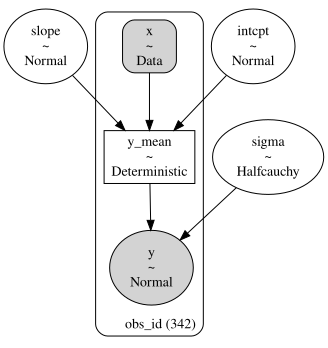

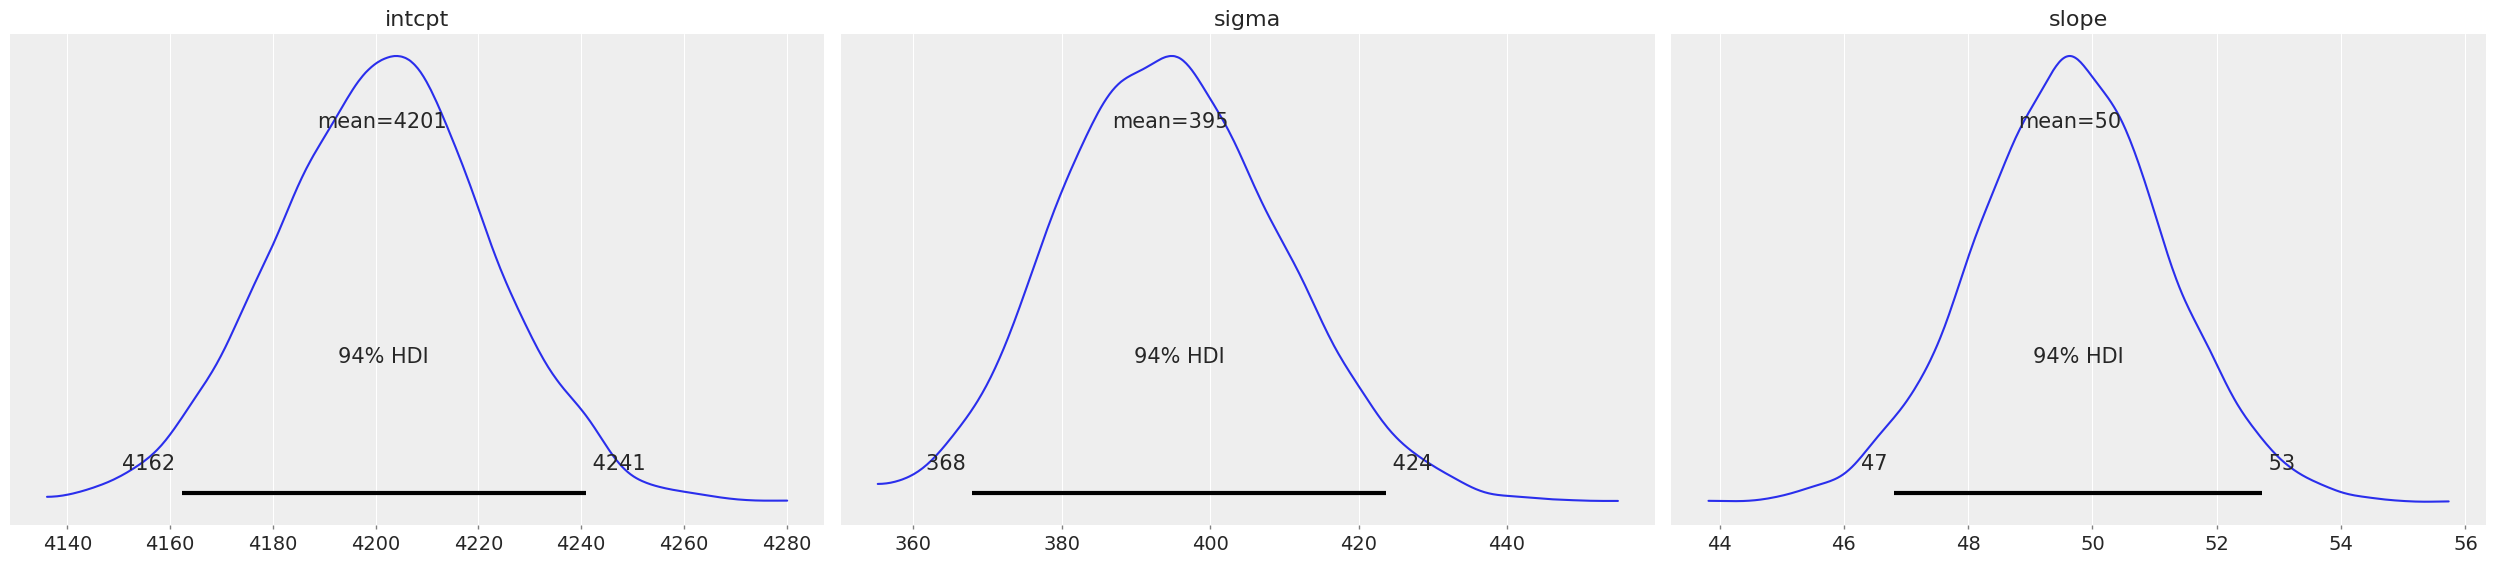

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
intcpt,4201.298,20.967,4162.203,4240.873,0.316,0.297,4426.0,3281.0,1.0
slope,49.635,1.555,46.809,52.732,0.026,0.025,3555.0,2865.0,1.0
sigma,394.673,14.949,367.949,423.638,0.245,0.222,3750.0,2826.0,1.0


In [6]:
with pm.Model() as regress:
    sigma = pm.HalfCauchy("sigma", beta=2)
    intcpt = pm.Normal("intcpt", 0, sigma=4000)   # grams; mean mass is ~4200
    slope = pm.Normal("slope", 0, sigma=50)       # g per mm of centered flipper
    x = pm.Data("x", peng["x"].to_numpy(), dims="obs_id")
    y_mean = pm.Deterministic("y_mean", intcpt + slope * x, dims="obs_id")
    pm.Normal("y", mu=y_mean, sigma=sigma, observed=peng["y"].to_numpy(), dims="obs_id")
    idata = pm.sample(2000, chains=2, tune=1000, random_seed=2, target_accept=0.9)

show_model(regress)
az.plot_posterior(idata, var_names=["~y_mean"])
plt.show()
display(az.summary(idata, var_names=["intcpt", "slope", "sigma"]))



---

**Lecture question**

What is this PyMC model doing? Why are the priors reasonable? What's HalfCauchy?

**Answer**

Likelihood: $y_i \sim N(\beta_0+\beta_1 x_i,\sigma^2)$ with $x$ centered flipper length. Unknowns $(\beta_0,\beta_1,\sigma)$ get independent priors; NUTS draws from the joint posterior.

**HalfCauchy($\beta=2$).** A Cauchy truncated to $\sigma>0$. Density $\propto (1+(\sigma/\beta)^2)^{-1}$ on $(0,\infty)$: heavy tail, no finite mean, weakly informative. It regularises $\sigma$ away from 0 more gently than a tight HalfNormal and does not impose a hard upper bound (unlike Uniform(0,S)). Gelman's weakly-informative default for scales.

**Are they reasonable?** After centering, $\beta_0$ is mean mass at mean flipper ($\sim 4200$ g); $N(0,4000^2)$ is wide on that scale. $\beta_1$ in g/mm: a 50 g/mm prior SD allows huge slopes relative to biology (penguins don't gain 50 g per mm typically — the posterior will shrink this). If we had used $N(0,5)$ as in the lecture's *standardized* $x$, it would be dogmatically tight on raw grams. Priors must match *units*. That is the critical lesson the lecture's $\sigma=5$ hid.

The pooled model is still Simpson-vulnerable: a beautiful posterior on the wrong slope.



### Separate predictive model

Inference conditions on the observed $x$. Prediction needs a new $x$-grid. Splitting the models is optional but clean: the likelihood with observed $y$ does not have to change length. `sample_posterior_predictive` is **not** a new MCMC — it plugs posterior draws into the sampling distribution. Deterministic `y_hat` is just arithmetic; random `y_pred` draws a Normal (in software: inverse-CDF / ziggurat-style Normal generator).



Output()

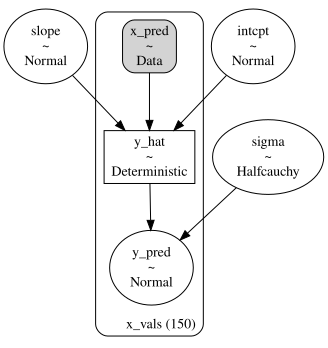

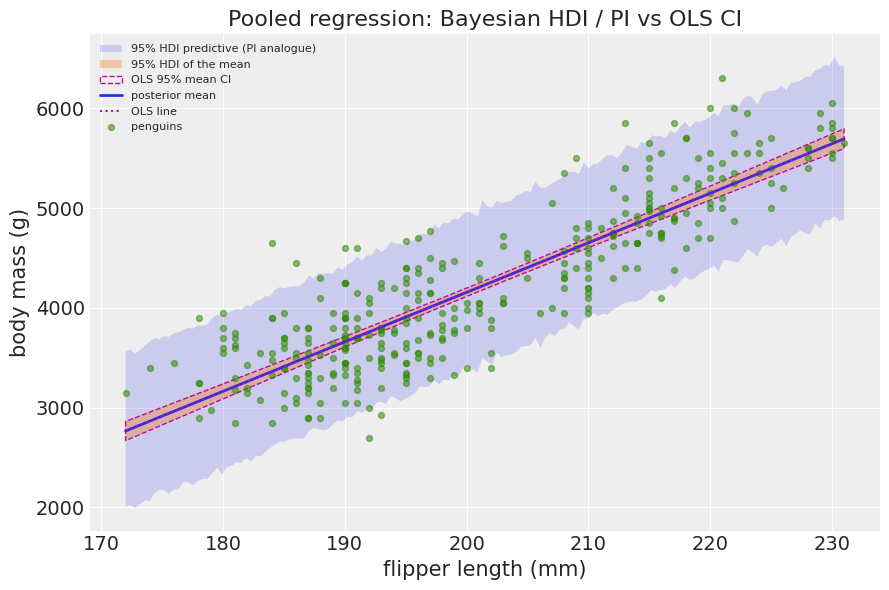

In [7]:
with pm.Model() as regress_pred:
    intcpt = pm.Normal("intcpt", 0, 4000)
    slope = pm.Normal("slope", 0, 50)
    sigma = pm.HalfCauchy("sigma", 2)
    x_pred = pm.Data("x_pred", x_grid, dims="x_vals")
    y_hat = pm.Deterministic("y_hat", intcpt + slope * x_pred, dims="x_vals")
    pm.Normal("y_pred", mu=y_hat, sigma=sigma, dims="x_vals")
    ppc = pm.sample_posterior_predictive(idata, var_names=["y_hat", "y_pred"], random_seed=2)

show_model(regress_pred)

y_hat_draws = (
    ppc.posterior_predictive["y_hat"].stack(sample=("chain", "draw")).transpose("sample", "x_vals").values
)
y_pred_draws = (
    ppc.posterior_predictive["y_pred"].stack(sample=("chain", "draw")).transpose("sample", "x_vals").values
)
mean_line = y_hat_draws.mean(axis=0)
hdi_mean = np.array([az.hdi(col, hdi_prob=0.95) for col in y_hat_draws.T])
hdi_pred = np.array([az.hdi(col, hdi_prob=0.95) for col in y_pred_draws.T])

fig, ax = plt.subplots(figsize=(9, 6))
ax.fill_between(x_grid + peng["x_raw"].mean(), hdi_pred[:, 0], hdi_pred[:, 1],
                alpha=0.18, label="95% HDI predictive (PI analogue)")
ax.fill_between(x_grid + peng["x_raw"].mean(), hdi_mean[:, 0], hdi_mean[:, 1],
                alpha=0.35, label="95% HDI of the mean")
ax.fill_between(x_grid + peng["x_raw"].mean(), pred_df["mean_ci_lower"], pred_df["mean_ci_upper"],
                color="none", edgecolor="C3", ls="--", label="OLS 95% mean CI")
ax.plot(x_grid + peng["x_raw"].mean(), mean_line, lw=2, label="posterior mean")
ax.plot(x_grid + peng["x_raw"].mean(), pred_df["mean"], color="C3", ls=":", label="OLS line")
ax.scatter(peng["x_raw"], peng["y"], s=18, alpha=0.55, label="penguins")
ax.set_xlabel("flipper length (mm)")
ax.set_ylabel("body mass (g)")
ax.set_title("Pooled regression: Bayesian HDI / PI vs OLS CI")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()



---

**Lecture question**

We've defined an inference model and a separate predictive model. Why is this separation sensible? Is it required?
Why is `pm.sample_posterior_predictive()` not outputting MCMC diagnostics like `pm.sample()`?
How can we draw samples of y_hat without running MCMC? Remember it's deterministic. What about y? That one isn't deterministic.

What's the difference between HDIs and PIs? Why are the PIs of constant size while the HDIs shrink towards the middle range?

**Answer**

Separation is bookkeeping: observed $y$ has length $n$; a grid has length 150. Keeping them in one model requires `pm.set_data` and matching observed length, which is easy to get wrong. It is *not* required — you can put both `x_obs` and `x_grid` in one graph. The posterior on $(\beta_0,\beta_1,\sigma)$ is what matters; prediction is a derived map.

`sample_posterior_predictive` is **not MCMC**. It conditions on already-accepted posterior draws and simulates from $p(\tilde y\mid\theta^{(s)})$. There is no proposal, no $\hat R$, no divergences. If MCMC failed, predictives fail silently downstream — diagnose `idata` first.

**`y_hat`** is $\beta_0^{(s)}+\beta_1^{(s)} x^*$: arithmetic. **`y_pred`** is $N(y_hat,\sigma^{(s)})$: a Normal draw (inverse-CDF / ziggurat). The extra noise is $\sigma$, not Monte Carlo error.

**HDI vs PI.** Mean HDI = uncertainty in the *conditional mean* $\mu(x)$. Predictive interval (PI) = uncertainty in a *new* $y$ at that $x$, i.e. posterior of $\mu(x)+\varepsilon$. In a homoscedastic linear model, $\mathrm{Var}(\hat\mu(x))\propto \frac{1}{n}+\frac{(x-\bar x)^2}{\sum(x_i-\bar x)^2}$ shrinks at $\bar x$ and flares at the edges (same as OLS mean CI). $\mathrm{Var}(y_{\mathrm{new}}\mid x)=\mathrm{Var}(\mu(x)\mid y)+\sigma^2$ is dominated by $\sigma^2$, so the PI looks almost constant-width. OLS prediction intervals are the frequentist analogue; they are not posterior probabilities.

**Criticism.** Constant-width PIs are an assumption, not a finding. If Gentoo are more variable, a single $\sigma$ is wrong and both OLS PI and Bayesian PI are miscalibrated — another reason to go hierarchical with `sigma[group]`.



**HDI vs PI.** The mean HDI is uncertainty in the *line* and shrinks near $\bar x$ (same geometry as the OLS mean CI). The predictive interval adds $\sigma$ and stays roughly constant width if $\sigma$ is constant. OLS prediction intervals are the frequentist analogue of the PI; Bayesian HDIs are posterior probability statements.

## 4. Joint posterior, KDE, and the grid method

PyMC approximates the joint posterior by MCMC samples; ArviZ then draws a KDE on those samples. A **grid** evaluates prior × likelihood on a mesh — exact up to discretization, but $O(k^d)$ in $d$ parameters, and you must guess the support before you see the posterior. In high $d$ almost all of the cube is empty (curse of dimensionality).



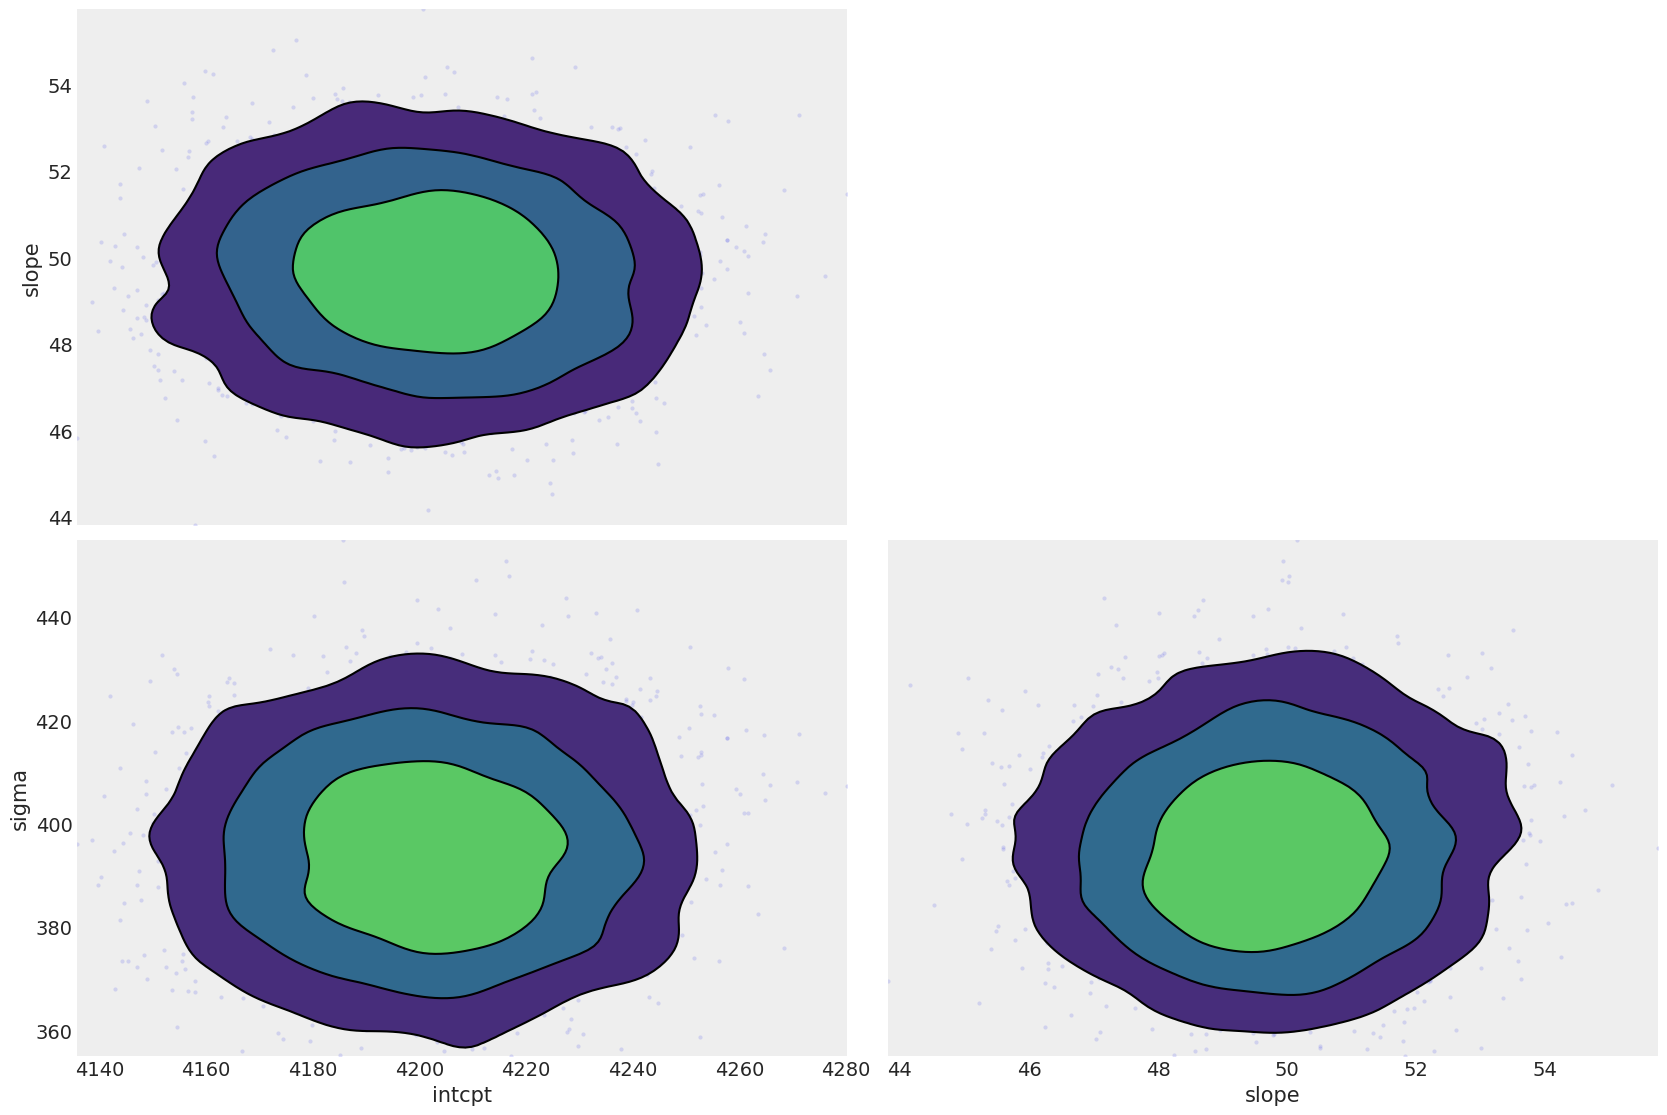

In [8]:
az.plot_pair(idata, var_names=["intcpt", "slope", "sigma"], kind=["kde", "scatter"],
             scatter_kwargs=dict(alpha=0.15))
plt.show()



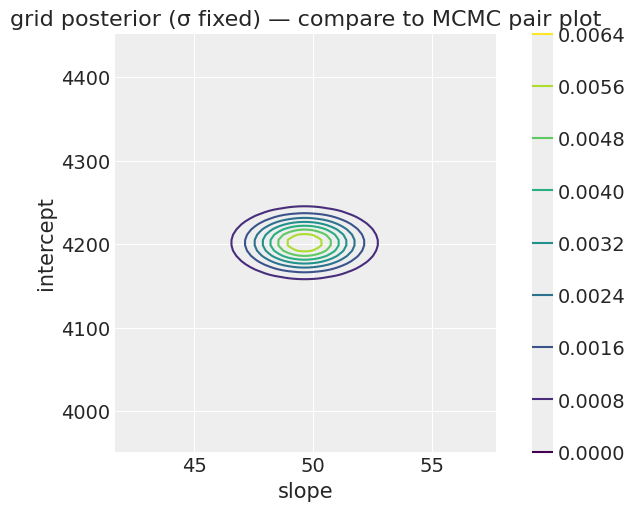

In [9]:
# grid on (intercept, slope) with sigma fixed at the OLS residual SD — 2-D illustration
sigma_fix = float(ols.resid.std(ddof=1))
n = 80
intcpt_sup = np.linspace(ols.params[0] - 250, ols.params[0] + 250, n)
slope_sup = np.linspace(ols.params[1] - 8, ols.params[1] + 8, n)
prior_i = stats.norm.pdf(intcpt_sup, loc=0, scale=4000)
prior_s = stats.norm.pdf(slope_sup, loc=0, scale=50)

# log-space to avoid underflow (the lecture's "why is this line problematic?")
log_post = np.empty((n, n))
x_obs = peng["x"].to_numpy()
y_obs = peng["y"].to_numpy()
for i, b0 in enumerate(intcpt_sup):
    for j, b1 in enumerate(slope_sup):
        mu = b0 + b1 * x_obs
        loglik = stats.norm.logpdf(y_obs, loc=mu, scale=sigma_fix).sum()
        log_post[i, j] = np.log(prior_i[i] + 1e-300) + np.log(prior_s[j] + 1e-300) + loglik
log_post -= log_post.max()
posterior = np.exp(log_post)
posterior /= posterior.sum()

fig, ax = plt.subplots(figsize=(6, 5))
cs = ax.contour(slope_sup, intcpt_sup, posterior, levels=8)
fig.colorbar(cs, ax=ax)
ax.set_xlabel("slope")
ax.set_ylabel("intercept")
ax.set_title("grid posterior (σ fixed) — compare to MCMC pair plot")
plt.show()



---

**Lecture question**

Why does the joint posterior of slope and intercept look like a 2-D Gaussian?
How does PyMC estimate the joint dist.? Mention MCMC and KDE.
Is it possible to approximate the joint posterior without sampling? Mention the grid method.
Why is `posterior[i,j] = prior * likelihood` on a raw product problematic? Mention underflow.
Why is the grid method only viable for 1–3 parameters? (1) computational complexity (2) curse of dimensionality / missing the typical set (3) having to know the support before seeing the data.

**Answer**

With a Gaussian likelihood, linear mean, and Gaussian priors, the posterior on $(\beta_0,\beta_1)$ (σ fixed) *is* Gaussian. The elliptical contour is the Normal theory OLS covariance, slightly regularised by the prior. If $x$ were not centered, the ellipse would tilt more: intercept and slope are negatively correlated because raising $\beta_0$ and lowering $\beta_1$ can fit the same cloud.

PyMC does not store a density on a grid. It stores *samples*. `plot_pair(..., kind='kde')` fits a kernel density to those samples. The KDE is a second approximation on top of MCMC.

**Grid.** Evaluate $\pi(\theta)L(y\mid\theta)$ on a mesh, normalise. No sampling. The lecture's raw product `prior_i[i]*prior_s[j]*likelihood[i,j]` **underflows**: a Normal log-likelihood of hundreds of penguins is $\sim -10^3$ to $-10^6$; `exp` of that is 0 in float64, so the whole grid becomes 0/0. Always add in the log, subtract the max, then exponentiate (as the cell does).

**Why 1–3 parameters.** (1) Cost $O(k^d)$ likelihoods. $k=80,d=5$ is already $80^5\approx 3\cdot 10^9$. (2) In high $d$ the posterior typical set is a thin shell; a cube grid wastes almost all nodes on exponentially small tails and still misses the ridge. (3) You must pick `linspace` bounds *before* seeing the posterior. Too narrow ⇒ truncated posterior. Too wide ⇒ even coarser mesh. MCMC discovers the typical set; a grid cannot.

**Criticism.** Our grid also *fixed* $\sigma$. That hides the 3-D geometry. A 3-D grid is already unpleasant. That is why we stop pretending and use HMC.



---

**Lecture question**

1. What are common failure modes of Metropolis–Hastings with a Gaussian proposal?
2. What makes a proposal heuristic good?
3. What's Hamiltonian MC? Explain as if I know no physics.
4. How does NUTS improve on HMC?
5. HMC/NUTS need gradients of the log posterior, but we're using them to *estimate* the posterior. How does PyMC get gradients?
6. What if my model has discrete parameters?

**Answer**

**MH failures.** Step too small: crawl, high ESS disaster. Step too large: reject almost everything. Anisotropic posterior (correlation between intercept and slope): a spherical Gaussian proposal moves the wrong way. Changing curvature (funnels): no single step size works.

A good proposal matches local scale and orientation of the posterior (adaptive covariance, or better, gradient information). High acceptance is *not* the goal; random-walk with 99% acceptance is too timid.

**HMC without physics.** Pretend the log-posterior is a hill. Give the current point a random velocity and slide it along the hill using the slope (gradient) so it can travel far without the drunkard's walk. Then accept/reject the landing point with a Metropolis correction for numerical error. You get distant, high-acceptance proposals in smooth continuous spaces.

**NUTS.** HMC needs a trajectory length. Too short = random walk; too long = U-turn (you come back). NUTS builds the trajectory until it would U-turn, so you do not tune that length by hand.

**Gradients.** Automatic differentiation through the computational graph of $\log p(y,\theta)=\sum_i \log N(y_i; \beta_0+\beta_1 x_i,\sigma)+\log\pi(\theta)$. Nobody differentiates the unknown posterior normaliser; the gradient of $\log p(y)$ is zero in $\theta$. For this regression the gradient w.r.t. $\beta_1$ is $\sum_i (y_i-\mu_i)x_i/\sigma^2$ plus the prior term — OLS's score function.

**Discrete parameters.** Leapfrog needs a derivative. PyMC samples discrete RVs with Metropolis / Gibbs / Particle Gibbs and continuous ones with NUTS, or you marginalise the discrete variables. A hierarchical discrete-and-funnel model is a notorious pain.



## 6. Hierarchical regression (centered) — where MCMC can hurt

Each species gets its own intercept and slope, shrunk toward hyper-means. This is the right scientific model if pooling is Simpson-biased. The **centered** parameterization `β ~ N(μ, σ_β)` becomes a **Neal funnel** when `σ_β` is small: group effects are squeezed into a spike. HMC divergences are failed leapfrog trajectories — the sampler is telling you the geometry is bad, not that the science is wrong.



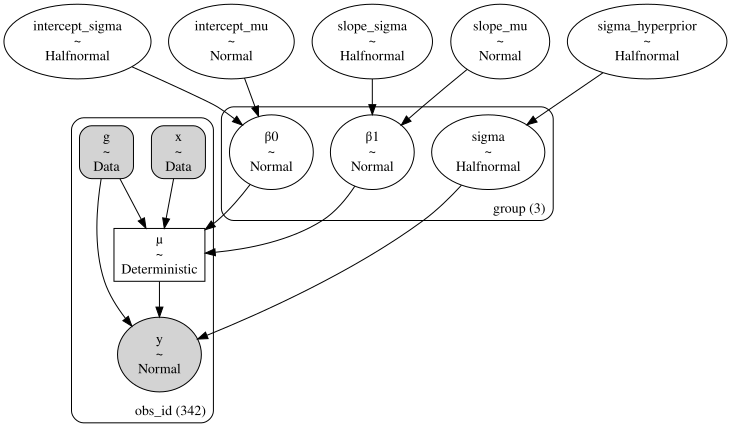

Output()

ERROR:pymc.stats.convergence:There were 8 divergences after tuning. Increase `target_accept` or reparameterize.


In [10]:
coords = {"group": group_list}
g_idx = peng["group_idx"].to_numpy()
x_obs = peng["x"].to_numpy()
y_obs = peng["y"].to_numpy()

with pm.Model(coords=coords) as hierarchical:
    intercept_mu = pm.Normal("intercept_mu", 4200, sigma=500)
    intercept_sigma = pm.HalfNormal("intercept_sigma", sigma=400)
    slope_mu = pm.Normal("slope_mu", 0, sigma=30)
    slope_sigma = pm.HalfNormal("slope_sigma", sigma=20)
    sigma_hyperprior = pm.HalfNormal("sigma_hyperprior", sigma=200)

    sigma = pm.HalfNormal("sigma", sigma=sigma_hyperprior, dims="group")
    β0 = pm.Normal("β0", intercept_mu, sigma=intercept_sigma, dims="group")
    β1 = pm.Normal("β1", slope_mu, sigma=slope_sigma, dims="group")

    x = pm.Data("x", x_obs, dims="obs_id")
    g = pm.Data("g", g_idx, dims="obs_id")
    μ = pm.Deterministic("μ", β0[g] + β1[g] * x, dims="obs_id")
    pm.Normal("y", mu=μ, sigma=sigma[g], observed=y_obs, dims="obs_id")

show_model(hierarchical)
with hierarchical:
    # deliberately short: we *want* to see fragile geometry if it appears
    idata_h = pm.sample(400, chains=2, tune=400, random_seed=2, target_accept=0.8)



---

**Lecture question**

<Copy & paste the sampling output.> Should I worry?

**Answer**

Worry if any of these fire: divergences > 0, $\hat R>1.01$, ESS of hundreds claimed as thousands, traces whose KDEs disagree, energy Bayesian fraction of missing information (E-BFMI) low. Do *not* worry about a mildly ugly trace on a parameter you will not interpret, until you have checked the ones you will.

We sampled **short on purpose** (400 draws, `target_accept=0.8`) so that if the centered funnel is present, it has a chance to show. A clean short run is not a proof of safety; a dirty short run is a proof of trouble. The scientific model can be right while the *geometry* is hostile — that is the whole point of this section.



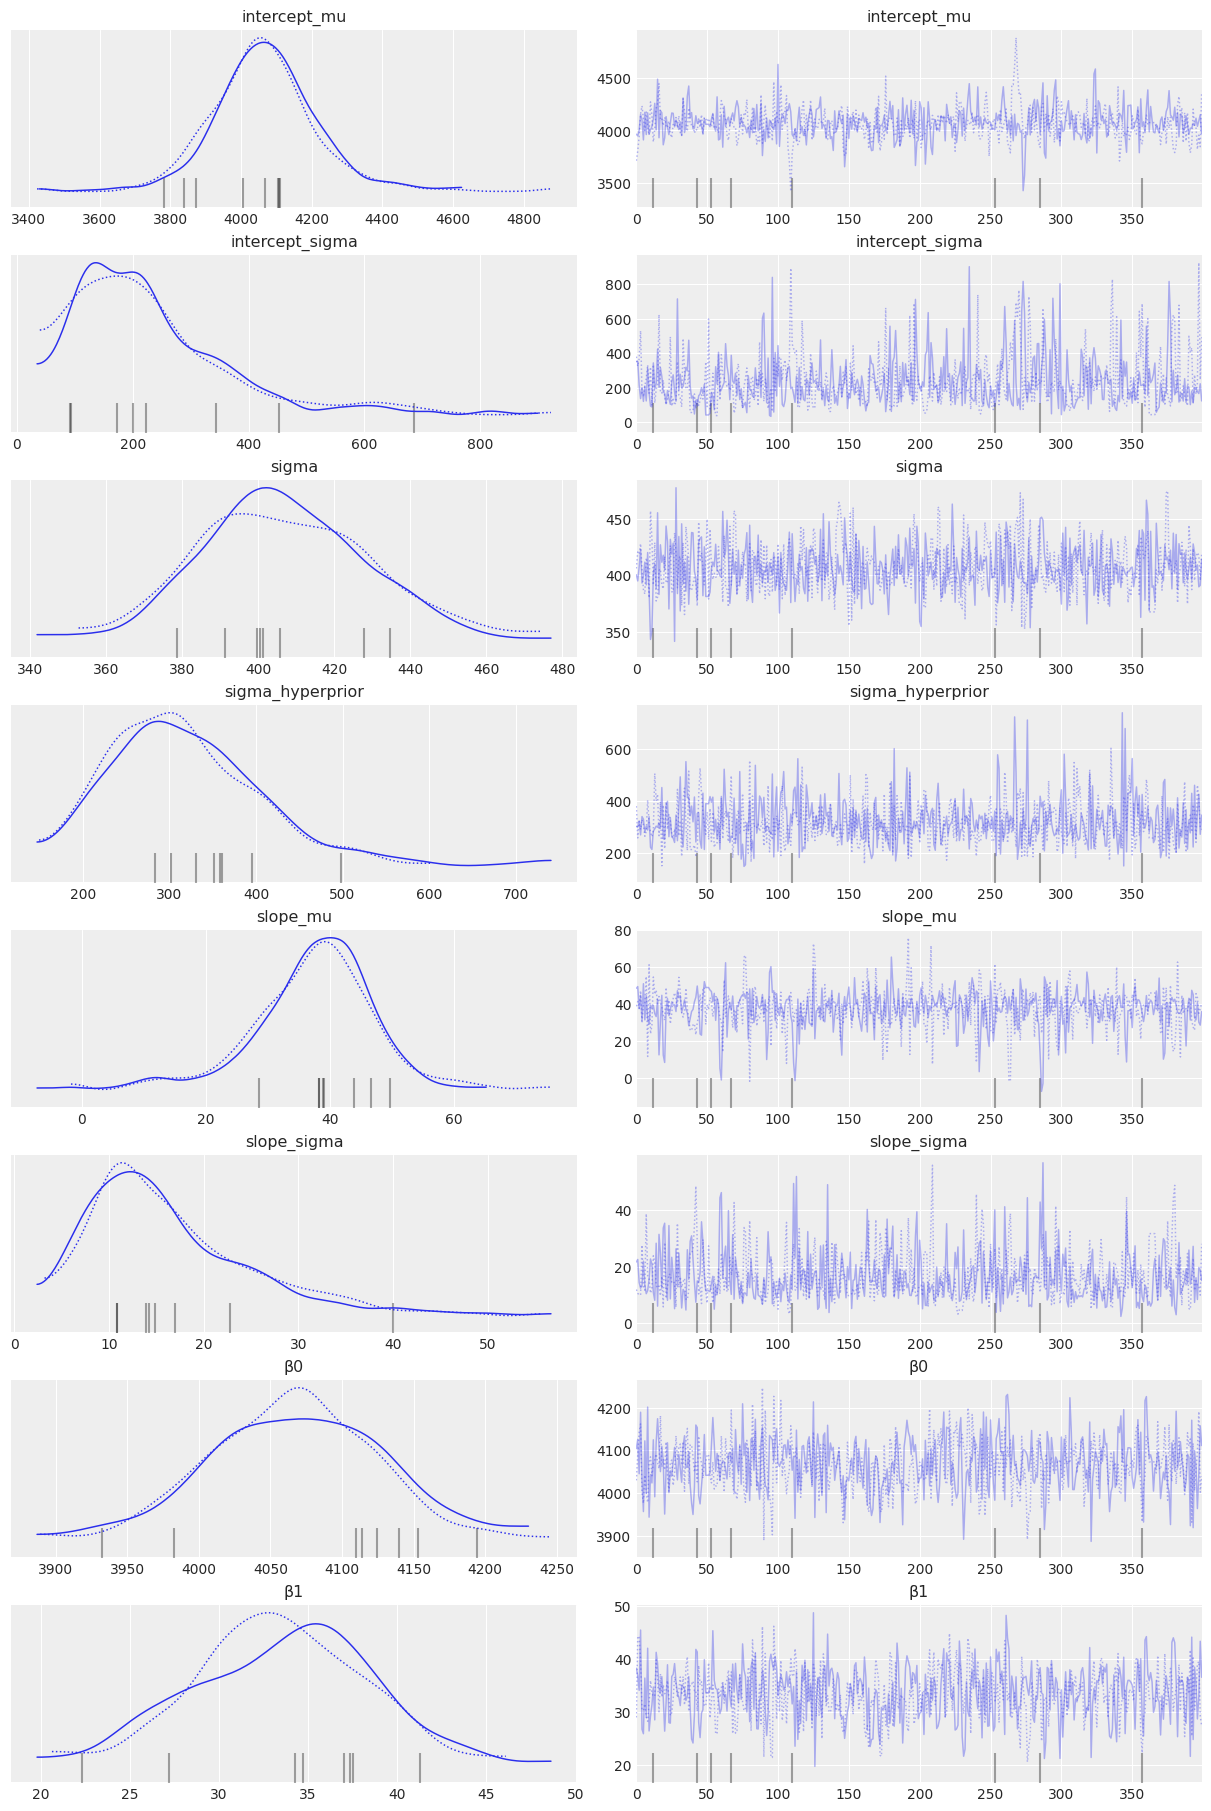

In [11]:
az.plot_trace(idata_h, var_names=["~μ"], coords={"group": group_list[0]}, figsize=(12, 18))
plt.show()



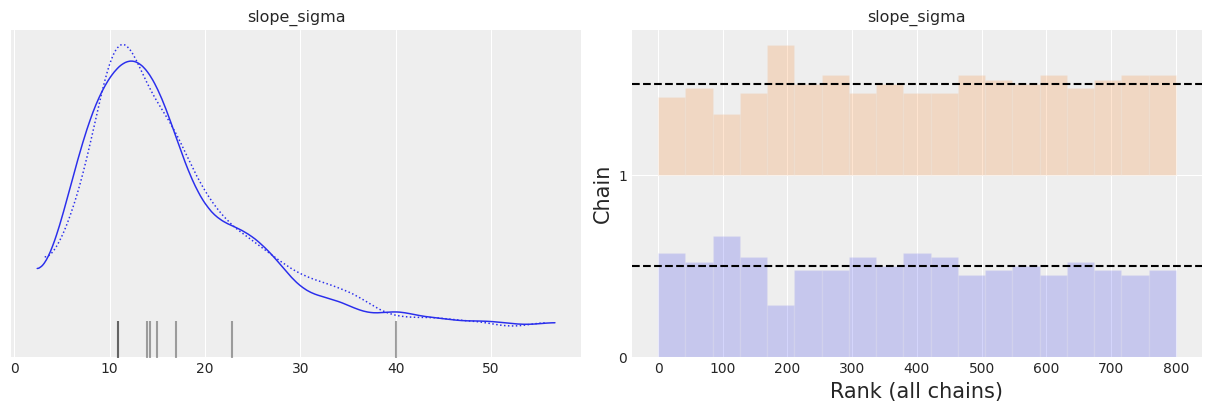

In [12]:
az.plot_trace(idata_h, kind="rank_bars", var_names=["slope_sigma"], figsize=(12, 4))
plt.show()
# Rank plot: all draws, ranked globally, histogrammed by chain.
# Good mixing ⇒ each chain looks like a uniform on ranks (flat bars).



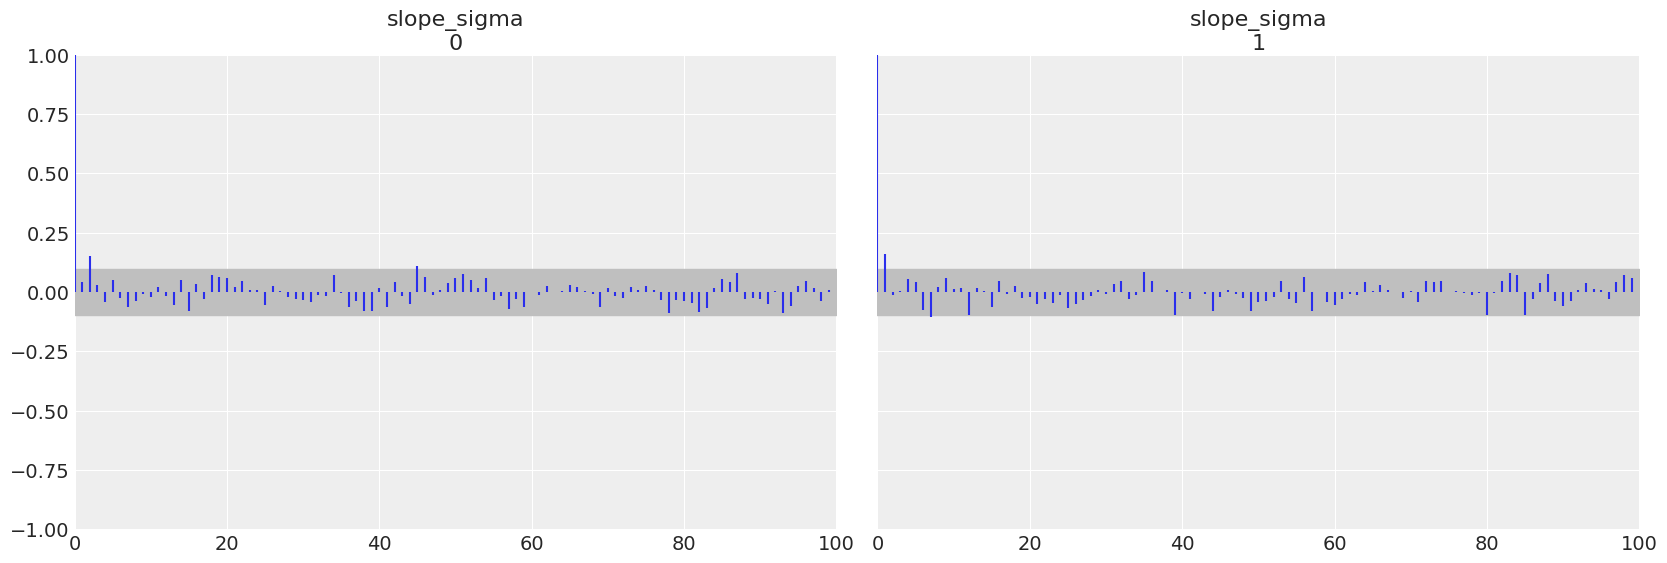

In [13]:
az.plot_autocorr(idata_h, var_names=["slope_sigma"])
plt.show()
# ArviZ autocorrelation: corr(θ_t, θ_{t+lag}) inside each chain after warmup.
# Slow decay ⇒ you have far fewer *effective* draws than raw draws.



---

**Lecture question**

Explain the rank-bar figure.
How does ArviZ calculate the autocorrelation here?

**Answer**

**Rank bars.** Pool all post-warmup draws of a parameter, replace them by their ranks, then histogram ranks *by chain*. If chains mix to the same distribution, each chain's ranks are like a random split of $\{1,\ldots,N\}$ — bars look flat. A chain that sat in a corner occupies only low or only high ranks: a spike. This detects the failure mode where two chains have similar means (so a naive overlay looks ok) but different spreads.

**Autocorrelation.** For chain $c$, ArviZ estimates $\rho_\ell =\mathrm{Corr}(\theta_t,\theta_{t+\ell})$ at lag $\ell$ after warmup, typically via FFT of the centered series. The plot is $\rho_\ell$ vs $\ell$. Independent draws ⇒ $\rho_\ell\approx 0$ after lag 1. A slow decay means a long memory: 1000 draws might be ~50 independent ones. ESS is essentially $n / \sum_\ell \rho_\ell$ (with truncation). Different chains can have different $\rho$; report the worst.

**Criticism.** Rank plots need ≥2 chains. Autocorrelation assumes approximate stationarity after warmup; if warmup was too short, $\rho_\ell$ is fiction.



### Where is the funnel?

`β1 ~ N(slope_mu, slope_sigma)`: when `slope_sigma → 0`, all species slopes collapse onto `slope_mu`. Pair plots with `divergences=True` mark the failed steps — typically the neck of the funnel.



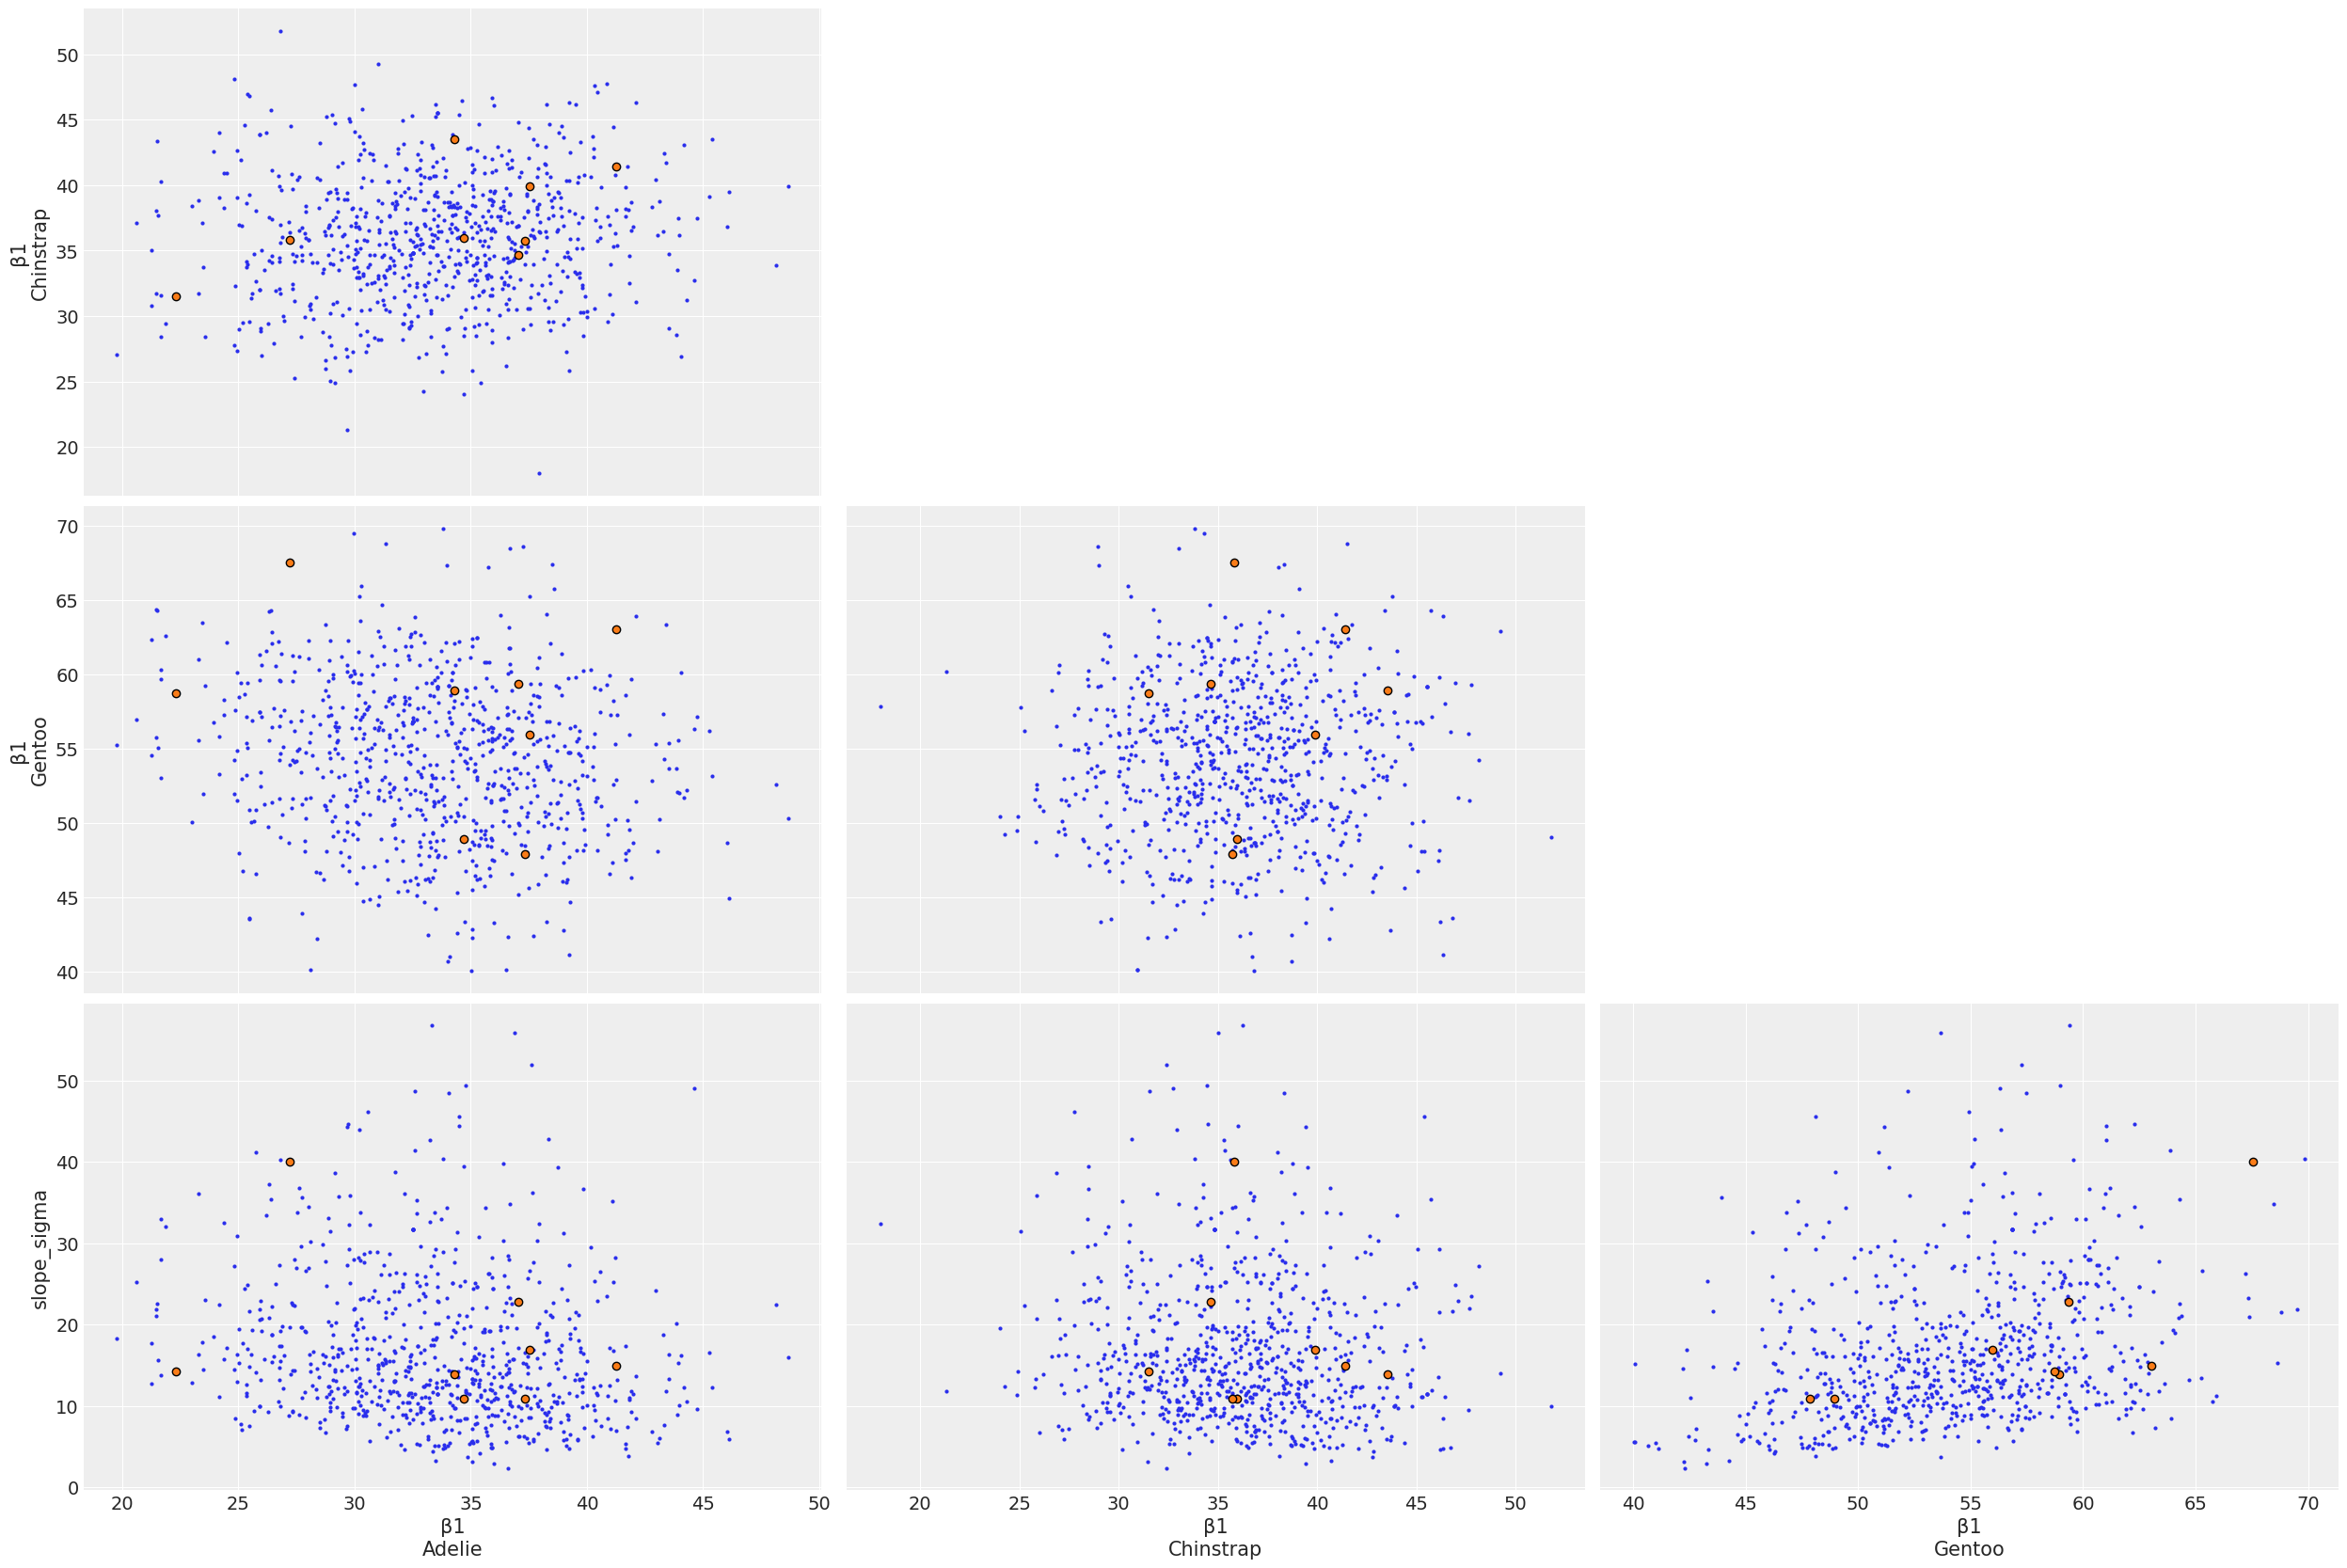

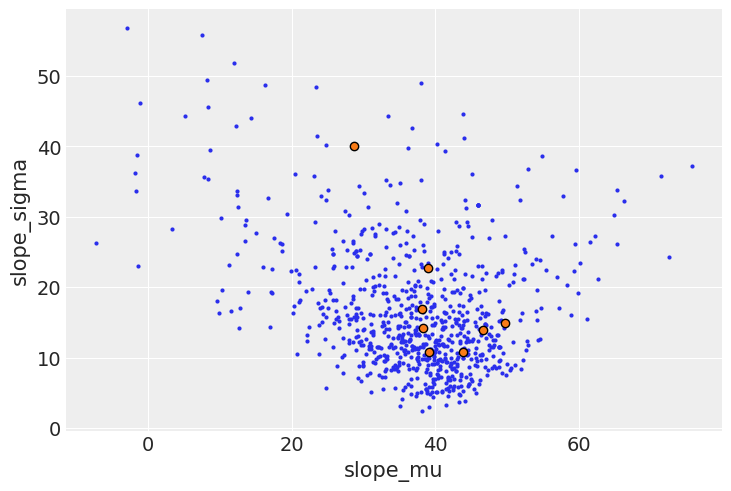

In [14]:
az.plot_pair(idata_h, var_names=["β1", "slope_sigma"], divergences=True)
plt.show()
az.plot_pair(idata_h, var_names=["slope_mu", "slope_sigma"], divergences=True)
plt.show()



---

**Lecture question**

Explain Neal's funnel and why Metropolis with fixed Gaussian steps fails there.
What are divergences in HMC? Why do they occur in the funnel? What does the algorithm do when a step diverges?
Where does a funnel occur in this model?

**Answer**

**Neal's funnel.** A density in which a scale $\sigma_\beta$ controls the spread of group effects $\beta_g\sim N(\mu,\sigma_\beta)$. When $\sigma_\beta$ is tiny, all $\beta_g$ sit in a needle; when it is large they fan out. The typical set is a funnel in $(\sigma_\beta,\beta_g)$.

Random-walk Metropolis with one step $\varepsilon$: in the neck $\varepsilon$ overshoots and rejects; in the mouth $\varepsilon$ crawls. No single $\varepsilon$ works.

**HMC divergences.** Leapfrog discretises a flow that assumes slowly changing curvature. In the neck the curvature explodes, energy is not conserved, the trajectory is numerical junk. NUTS **discards it and flags a divergence**. Red points on pair plots cluster in the neck. Divergences mean "integrator died," not "the science is bimodal."

**This model.** `β1 ~ N(slope_mu, slope_sigma)` — funnel in $(\texttt{slope_sigma},\beta_{1,g})$. Three penguin species identify $\sigma_\beta$ weakly, so the neck is tempting.

**Criticism.** Raising `target_accept` to 0.99 until divergences vanish can yield a sample that never entered the neck (bias). Reparameterise; do not only crank the dial.



### Quantitative diagnostics

- $\hat R$: between-chain vs within-chain variance. Near 1 means chains found the same place. Treat $> 1.01$ as a warning.
- **ess_bulk / ess_tail:** effective sample size for typical vs tail quantities. MCMC draws are correlated, so 800 raw draws might be ~80 independent ones.
- **ESS ≈ 400** is a common rule of thumb so Monte Carlo SE is small relative to posterior SD (MCSE $\approx \mathrm{SD}/\sqrt{\mathrm{ESS}}$).



,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
β1[Adelie],33.502,4.861,24.393,42.101,0.191,0.152,651.0,544.0,1.01
β1[Chinstrap],36.013,4.753,26.850,44.689,0.180,0.172,694.0,550.0,1.00
β1[Gentoo],54.267,5.203,44.499,63.189,0.232,0.226,509.0,484.0,1.01
slope_sigma,16.611,8.901,4.128,33.814,0.379,0.362,553.0,466.0,1.00
slope_mu,37.259,10.612,12.286,54.629,0.407,0.522,739.0,567.0,1.00


divergences: 8


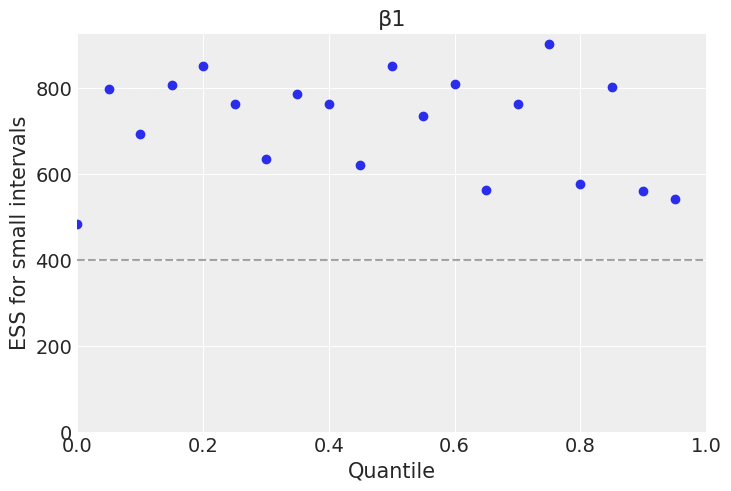

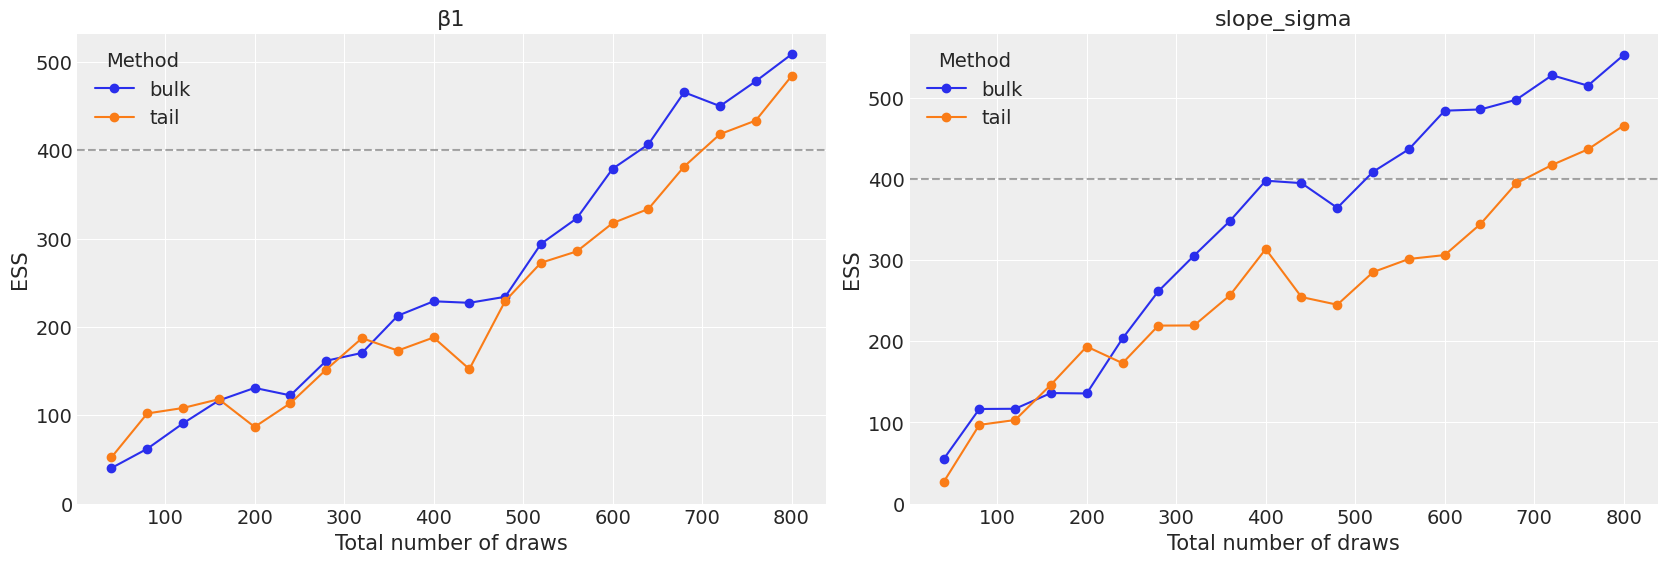

In [15]:
display(az.summary(idata_h, var_names=["β1", "slope_sigma", "slope_mu"]))
print("divergences:", int(idata_h.sample_stats["diverging"].sum()))
az.plot_ess(idata_h, var_names=["β1"], coords={"group": group_list[-1]})
plt.show()
az.plot_ess(idata_h, var_names=["β1", "slope_sigma"], coords={"group": group_list[-1]}, kind="evolution")
plt.show()



---

**Lecture question**

What do we see in `az.summary`? What's r_hat? What value should make me worry? (See Gelman's "maybe it's time to let the old ways die".)
What's ess_bulk and ess_tail? We asked for 2000 MCMC samples; why are these numbers lower?
Why is 400 the magic number for ESS? Mention MCSE.

**Answer**

`az.summary` reports posterior mean/sd, HDI, $\hat R$, ess_bulk, ess_tail, and Monte Carlo SE. **$\hat R$** compares between-chain to within-chain variance (split-chain version). Exactly 1 if chains are indistinguishable. The old "1.1 is fine" bar is too loose; Vehtari/Gelman argue for **1.01** as a diagnostic threshold, not a p-value. $\hat R<1.01$ is necessary, not sufficient (all chains can share the same bias).

**ESS.** MCMC draws are dependent. ess_bulk is the equivalent iid sample size for typical posterior quantities (mean, median); ess_tail for 5%/95% quantiles, which mix slower. 2000 raw draws with $\rho\approx 0.9$ can be ~100 effective draws. That is not a bug in ArviZ; it is the definition of mixing.

**Why ~400.** Monte Carlo SE of the mean is $\mathrm{SD}/\sqrt{\mathrm{ESS}}$. ESS=400 ⇒ MCSE ≈ 5% of the posterior SD, small enough that the reported HDI is not dominated by sampler noise. Tails need more. The ESS *evolution* plot should still be climbing; a plateau at 80 means more iterations will not help — reparameterise.

**Criticism.** ESS=400 on $\beta_1$ with ESS=20 on `slope_sigma` means you do not know the amount of shrinkage. Quote the worst relevant ESS, not the intercept's.



## 7. Non-centered reparameterization

Same *probability model*, different *sampling coordinates*:

$$
\beta = \mu + \sigma \cdot z, \quad z \sim N(0,1)
$$

That is the same trick as the VAE reparameterization: move noise to a fixed $N(0,1)$ so the geometry does not pinch when $\sigma$ is small. Brute-force alternative: more draws / more chains — only if the ESS *evolution* plot is still climbing.



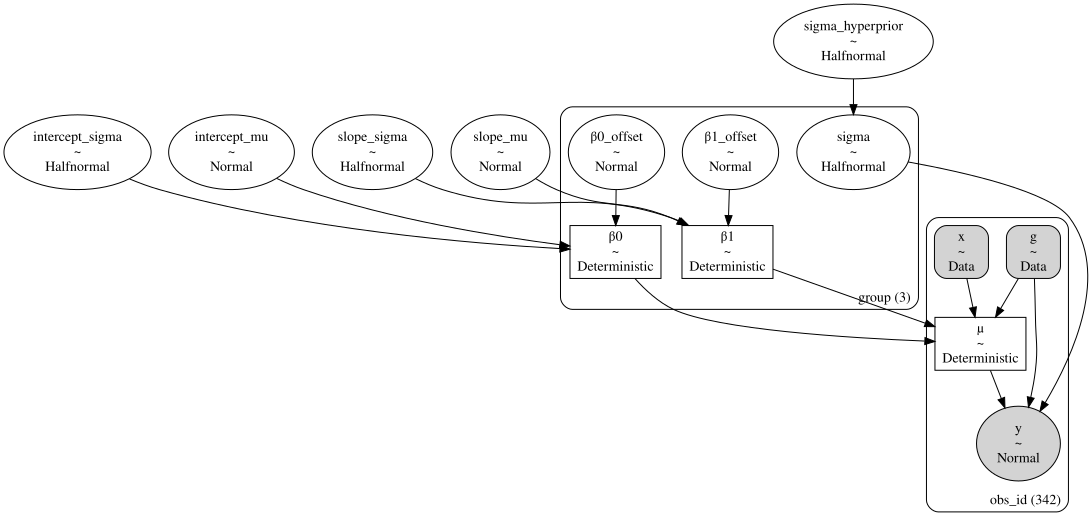

Output()

ERROR:pymc.stats.convergence:There were 8 divergences after tuning. Increase `target_accept` or reparameterize.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
β1[Adelie],33.839,4.695,25.338,42.565,0.104,0.089,2015.0,1494.0,1.0
β1[Chinstrap],36.052,4.958,27.017,45.678,0.103,0.108,2322.0,1498.0,1.0
β1[Gentoo],53.930,5.344,43.457,63.743,0.142,0.137,1449.0,1049.0,1.0
slope_sigma,16.585,8.809,3.373,33.817,0.306,0.295,804.0,808.0,1.0
slope_mu,37.108,10.993,15.036,56.597,0.468,0.616,697.0,518.0,1.0


divergences (non-centered): 8
divergences (centered):     8


In [16]:
with pm.Model(coords=coords) as hierarchical_nc:
    intercept_mu = pm.Normal("intercept_mu", 4200, sigma=500)
    intercept_sigma = pm.HalfNormal("intercept_sigma", sigma=400)
    slope_mu = pm.Normal("slope_mu", 0, sigma=30)
    slope_sigma = pm.HalfNormal("slope_sigma", sigma=20)
    sigma_hyperprior = pm.HalfNormal("sigma_hyperprior", sigma=200)

    sigma = pm.HalfNormal("sigma", sigma=sigma_hyperprior, dims="group")
    β0_offset = pm.Normal("β0_offset", 0, 1, dims="group")
    β0 = pm.Deterministic("β0", intercept_mu + β0_offset * intercept_sigma, dims="group")
    β1_offset = pm.Normal("β1_offset", 0, 1, dims="group")
    β1 = pm.Deterministic("β1", slope_mu + β1_offset * slope_sigma, dims="group")

    x = pm.Data("x", x_obs, dims="obs_id")
    g = pm.Data("g", g_idx, dims="obs_id")
    μ = pm.Deterministic("μ", β0[g] + β1[g] * x, dims="obs_id")
    pm.Normal("y", mu=μ, sigma=sigma[g], observed=y_obs, dims="obs_id")

show_model(hierarchical_nc)
with hierarchical_nc:
    idata_nc = pm.sample(1000, chains=2, tune=1000, random_seed=2, target_accept=0.9)

display(az.summary(idata_nc, var_names=["β1", "slope_sigma", "slope_mu"]))
print("divergences (non-centered):", int(idata_nc.sample_stats["diverging"].sum()))
print("divergences (centered):    ", int(idata_h.sample_stats["diverging"].sum()))



---

**Lecture question**

What's the difference between this model and the centered one? How does it solve the funnel?
Where have I seen this trick before? (Hint: VAE).

**Answer**

**Centered:** $\beta_g \sim N(\mu,\sigma_\beta)$ — the group parameter's prior *scale* depends on a random $\sigma_\beta$. **Non-centered:** $z_g\sim N(0,1)$, $\beta_g=\mu+\sigma_\beta z_g$. Same joint distribution on $(\beta,\mu,\sigma_\beta)$, different coordinates. When $\sigma_\beta\to 0$, $z_g$ stays $N(0,1)$ with no pinching; the funnel is flattened.

This is the **reparameterization trick** in VAEs: write $x=\mu+\sigma\odot \varepsilon$, $\varepsilon\sim N(0,1)$, so the noise does not depend on parameters you want to differentiate. HMC needs a density that does not change geometry when a scale parameter moves.

**When centered is better.** With *lots* of data per group, $\beta_g$ is well identified and centered can mix better. Non-centered shines when groups are weakly identified (three penguin species). There is no universally dominant parameterization — that is why both appear in the lecture.

Drawing a VAE graph is software; the statistical content is: move randomness onto a fixed standard Normal.



## 8. Classical grouped OLS — dummies and VIF

One-hot species indicators are the OLS version of “a different intercept per group.” Drop one column to avoid the **dummy-variable trap** (perfect collinearity with the intercept). **VIF** $= 1/(1-R^2_j)$ from regressing column $j$ on the others; $\infty$ means exact collinearity.



In [17]:
dummies = pd.get_dummies(peng["group"], prefix="sp", drop_first=True).astype(float)
X_full = pd.concat([peng[["x"]].astype(float), dummies], axis=1)
X_full = sm.add_constant(X_full)
ols_grp = sm.OLS(peng["y"].astype(float), X_full).fit()
print(ols_grp.summary())

print("\nVIF (with drop_first — should be finite):")
print(pd.Series([VIF(X_full.to_numpy(), i) for i in range(X_full.shape[1])], index=X_full.columns))

X_trap = sm.add_constant(pd.concat([peng[["x"]].astype(float),
                                    pd.get_dummies(peng["group"], prefix="sp", drop_first=False).astype(float)], axis=1))
print("\nVIF (all dummies + intercept — dummy trap):")
print(pd.Series([VIF(X_trap.to_numpy(), i) for i in range(X_trap.shape[1])], index=X_trap.columns))



                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.783
Model:                            OLS   Adj. R-squared:                  0.781
Method:                 Least Squares   F-statistic:                     405.7
Date:                Sun, 20 Sep 2026   Prob (F-statistic):          1.25e-111
Time:                        07:36:40   Log-Likelihood:                -2510.8
No. Observations:                 342   AIC:                             5030.
Df Residuals:                     338   BIC:                             5045.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const         4146.8570     45.466     91.208   

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


---

**Lecture question**

What's one-hot encoding? Why is it useful in OLS?
What's multicollinearity? The dummy-variable trap?
What's VIF? I got VIF = inf; what does it mean?
The intercept VIF is inflated even after drop_first. Why?

**Answer**

One-hot encoding turns a species label into columns 0/1. OLS is a linear map of columns; without dummies there is no "Gentoo intercept." With dummies you get a different intercept per species (the OLS cousin of hierarchical $\beta_{0g}$, *without* shrinkage).

**Dummy trap.** Columns $\mathbf{1}, d_1, d_2, d_3$ with $d_1+d_2+d_3=\mathbf{1}$ are linearly dependent. $X^\top X$ is singular, coefficients are not identified, VIF $=\infty$. Drop one species (or drop the intercept).

**VIF**$_j=1/(1-R^2_j)$ from regressing column $j$ on the others. 1 = orthogonal. 5–10 = uncomfortable. $\infty$ = exact collinearity.

After `drop_first`, intercept VIF can still be large if the remaining dummies plus $x$ jointly predict the constant well (unbalanced species sizes, $x$ correlated with species — Gentoo have longer flippers). That is *not* the dummy trap; it is ordinary collinearity. The slope of $x$ can still be fine. Look at VIF of $x$ and whether species-adjusted $\hat\beta_1$ matches the hierarchical $\beta_1$.

**Vs Bayes.** OLS dummies = no pooling of intercepts. Hierarchical = partial pooling. If a species had $n=3$, OLS dummy SEs explode; the hierarchical intercept shrinks.



## 9. Takeaways

| piece | classical | Bayesian |
|---|---|---|
| pooled line | `sm.OLS`, mean CI, prediction interval | `pm.Normal` mean, HDI, posterior predictive PI |
| groups | dummies, VIF, dummy trap | hierarchical $\beta_g$, shrinkage |
| geometry | (not a sampling issue) | funnel, divergences, non-centered $z$ |
| “did MCMC work?” | n/a | $\hat R$, ESS, rank plots, autocorrelation |

The pooled slope here is a species-mix artefact as much as a biological constant — same moral as the lecture’s Simpson simulation, on real penguins.

